# Step 46 — Driving-licence model: who holds a car licence, and how many will in 2040 and 2050

A binary logit of car-licence holding, estimated on the persons of the 2017–18 travel habits
survey (THS) and applied to the zonal population of the BU and HS demographic scenarios. The
product is the number of licence holders per zone, sector and age band in each scenario year.

**Every predictor exists in the forecast zonal files**: age, gender, sector (Arab / Haredi /
rest) and the zone's socio-economic index and ring. Household cars, employment and education
predict the licence better, but they are decided together with it and the forecast does not
carry them per person, so they are left out.

**Two forecasts are reported side by side.**
- *Static* — the 2017 rate of each age applied to the scenario year. It reads the generation
  gap in the survey as an ageing effect, so it is a lower bound.
- *Cohort carry-forward* (adopted) — a licence, once obtained, is never given up. Each birth
  cohort holds the highest rate of the 2017 profile between its age in 2017 and its age in the
  forecast year: a cohort past the peak in 2017 keeps the rate it had, a younger one takes the
  peak of its gender, sector and zone.

The functions are in `tools/licence_model.py` (tests: `python3 tools/test_licence_model.py`).
Design: `docs/superpowers/specs/2026-11-16-driving-licence-model-design.md`. METHODOLOGY §6at.

In [1]:
# All paths in this notebook are relative to the repository root; anchor the working directory there
import os, sys
while not os.path.exists('METHODOLOGY.md') and os.getcwd() != '/': os.chdir('..')
assert os.path.exists('METHODOLOGY.md'), 'run from inside the Nofit_LRT_Extension repository'
sys.path.insert(0, 'tools')

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, log_loss
import licence_model as lm
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)

BLUE, ORANGE, AQUA, PURPLE, INK, INK2, MUTED, GRID, AXIS = '#2a78d6', '#eb6834', '#1baf7a', '#7b5bd6', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
OUT = 'Output/licence_model'; os.makedirs(OUT, exist_ok=True)
SEED = 46
SEC_NAME = {'ara': 'Arab', 'rest': 'Jewish (non-Haredi) and other', 'ort': 'Haredi'}
SEC_ORDER = ['ara', 'rest', 'ort']
SCEN = [('BU', 2040), ('BU', 2050), ('HS', 2040), ('HS', 2050)]
AGE_GROUPS = [17, 19, 26, 36, 45, 55, 65, 75, 121]
AGE_LABELS = ['17–18', '19–25', '26–35', '36–44', '45–54', '55–64', '65–74', '75+']
def agegrp(a): return pd.cut(a, AGE_GROUPS, right=False, labels=AGE_LABELS)
def wmean(x, w): return float(np.average(x, weights=w)) if len(x) else np.nan

## 1. The estimation sample

Persons aged 17 and over with a licence answer and a known gender. The dependent variable is
`license_car` (yes / no). Weight: the household expansion weight `wf_new`, normalised to the
sample size. Sector: `arab` → Arab, `orto` → Haredi, everything else (`secular`, `religious`,
`other`) → rest — the three groups of the forecast files. Zone attributes come from
`Input/Zonal_2020.csv`; a socio-economic index of 0 means *not classified* and is replaced by
the sample's weighted mean.

In [3]:
d = lm.load_persons('.')
allp = lm.load_persons('.', estimation=False)          # every person with age and gender: for the age / gender split inside the bands
FILL = lm.soceco_fill(d)
raw = pd.read_csv('Input/THS_2017-2018/PersonsFin2.csv', low_memory=False)
adults = raw[raw.Age >= 17]
print(f"persons in the file {len(raw):,}; aged 17+ {len(adults):,}; licence answered {adults.license_car.isin(['yes','no']).sum():,}; "
      f"and gender known = estimation sample {len(d):,} in {d.HHID.nunique():,} households")
print(f"licence rate: unweighted {d.lic.mean():.3f}, weighted {wmean(d.lic, d.w):.3f};  SOCECO stand-in for unclassified zones {FILL:.2f} "
      f"({(d.SOCECO == 0).sum()} persons)")
t = d.assign(g=agegrp(d.age), Gender=np.where(d.male == 1, 'men', 'women'), Sector=d.sec.map(SEC_NAME))
desc = t.groupby(['Sector', 'Gender']).apply(lambda x: pd.Series({'persons': len(x), 'licence rate (weighted)': wmean(x.lic, x.w)})).round(3)
desc

persons in the file 16,388; aged 17+ 11,262; licence answered 11,231; and gender known = estimation sample 10,895 in 5,037 households
licence rate: unweighted 0.707, weighted 0.709;  SOCECO stand-in for unclassified zones 4.91 (80 persons)


persons  licence rate (weighted)
Sector                        Gender                                  
Arab                          men      2254.0                    0.818
                              women    2068.0                    0.527
Haredi                        men       300.0                    0.690
                              women     327.0                    0.319
Jewish (non-Haredi) and other men      2805.0                    0.846
                              women    3141.0                    0.652

## 2. A held-out fifth of the households

Before anything is chosen on the full sample, 20 % of the **households** are set aside (whole
households, so that no person is predicted from a relative's answer). Each specification is
estimated on the other 80 % and scored on the held-out part: area under the ROC curve,
log-loss, and the predicted against the observed number of licence holders.

The specification ladder (`lm.SPECS`): M0 age curve (piecewise-linear, knots at 19, 26, 36, 65,
75) → M1 + gender → M2 + sector → M3 + sector × gender → M4 + gender × age and sector × age →
M5 + sector × gender × age → M6 + zone (socio-economic index, ring) → M7 + sector × index →
M8 + settlement size. The sector × age terms use reduced curves (Arab: knots 26, 36, 65;
Haredi: 26, 65): with the full curve the model separates, because no Arab woman of 80 or over
in the sample holds a licence.

In [4]:
def P(params, spec, t):
    return lm.predict(params, spec, t.age, t.male, t.sec, lm.clean_soceco(t.SOCECO, FILL), t.SETTL_SIZE, t.TABAAT)

tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(d, groups=d.HHID))
train, test = d.iloc[tr_i].copy(), d.iloc[te_i].copy()
train['w'] = train.wraw * len(train) / train.wraw.sum()
assert not set(train.HHID) & set(test.HHID)
print(f"training {len(train):,} persons / {train.HHID.nunique():,} households;  held out {len(test):,} persons / {test.HHID.nunique():,} households")
rows = []
for s in lm.SPECS:
    r = lm.fit(train, s, FILL); p = P(r.params, s, test)
    rows.append({'model': s, 'parameters': len(r.params), 'holdout AUC': roc_auc_score(test.lic, p, sample_weight=test.w),
                 'holdout log-loss': log_loss(test.lic, p, sample_weight=test.w),
                 'holdout observed rate': wmean(test.lic, test.w), 'holdout predicted rate': wmean(p, test.w)})
holdout = pd.DataFrame(rows).set_index('model'); holdout.to_csv(f'{OUT}/holdout_by_model.csv')
holdout.round(4)

training 8,704 persons / 4,029 households;  held out 2,191 persons / 1,008 households


,parameters,holdout AUC,holdout log-loss,holdout observed rate,holdout predicted rate
model,,,,,
M0,7,0.6871,0.5592,0.6911,0.7018
M1,8,0.7683,0.5176,0.6911,0.6964
M2,10,0.7870,0.5008,0.6911,0.6987
M3,12,0.7852,0.5013,0.6911,0.6990
M4,25,0.7933,0.4836,0.6911,0.6996
M5,32,0.7923,0.4835,0.6911,0.6999
M6,36,0.8234,0.4614,0.6911,0.6984
M7,38,0.8268,0.4577,0.6911,0.6979
M8,40,0.8272,0.4574,0.6911,0.6978


## 3. The specification ladder on the full sample

Log-likelihood, AIC, BIC, a Wald test of the terms each step adds (household-clustered
covariance), and five-fold cross-validation with whole households held out.

In [5]:
rows, fits, prev = [], {}, None
for s in lm.SPECS:
    r = lm.fit(d, s, FILL); fits[s] = r; k = len(r.params)
    new = [c for c in r.params.index if prev is not None and c not in prev.params.index]
    wald = r.wald_test(np.eye(k)[[list(r.params.index).index(c) for c in new]], scalar=True).pvalue if new else np.nan
    auc, ll = [], []
    for a, b in GroupKFold(5).split(d, groups=d.HHID):
        rr = lm.fit(d.iloc[a], s, FILL); t = d.iloc[b]; p = P(rr.params, s, t)
        auc.append(roc_auc_score(t.lic, p, sample_weight=t.w)); ll.append(log_loss(t.lic, p, sample_weight=t.w))
    rows.append({'model': s, 'adds': lm.SPECS[s][-1], 'parameters': k, 'log-likelihood': r.llf, 'AIC': -2 * r.llf + 2 * k,
                 'BIC': -2 * r.llf + k * np.log(len(d)), 'Wald p of added terms': wald, 'CV AUC': np.mean(auc), 'CV log-loss': np.mean(ll)})
    prev = r
ladder = pd.DataFrame(rows).set_index('model').join(holdout[['holdout AUC', 'holdout log-loss']])
ladder.to_csv(f'{OUT}/specification_ladder.csv')
ll0 = float((d.w * (d.lic * np.log(wmean(d.lic, d.w)) + (1 - d.lic) * np.log(1 - wmean(d.lic, d.w)))).sum())
print(f"constant-only log-likelihood {ll0:.1f}")
ladder.round({'log-likelihood': 1, 'AIC': 1, 'BIC': 1, 'Wald p of added terms': 4, 'CV AUC': 4, 'CV log-loss': 4, 'holdout AUC': 4, 'holdout log-loss': 4})

constant-only log-likelihood -6574.1


,adds,parameters,log-likelihood,AIC,BIC,Wald p of added terms,CV AUC,CV log-loss,holdout AUC,holdout log-loss
model,,,,,,,,,,
M0,age,7,-6009.5,12033.0,12084.1,NaN,0.6766,0.5526,0.6871,0.5592
M1,male,8,-5561.7,11139.4,11197.8,0.0000,0.7573,0.5117,0.7683,0.5176
M2,sec,10,-5426.7,10873.4,10946.3,0.0000,0.7723,0.4997,0.7870,0.5008
M3,sec_male,12,-5419.6,10863.1,10950.7,0.0054,0.7716,0.4993,0.7852,0.5013
M4,sec_age,25,-5255.0,10560.0,10742.4,0.0000,0.7793,0.4859,0.7933,0.4836
M5,sec_male_age,32,-5228.0,10519.9,10753.4,0.0000,0.7815,0.4857,0.7923,0.4835
M6,zone,36,-5000.4,10072.7,10335.4,0.0000,0.8077,0.4660,0.8234,0.4614
M7,zone_sec,38,-4970.7,10017.4,10294.7,0.0000,0.8105,0.4639,0.8268,0.4577
M8,settl,40,-4969.1,10018.2,10310.0,0.3956,0.8103,0.4640,0.8272,0.4574


**Choice: M7.** It has the lowest BIC and the best cross-validated and held-out scores of the
models whose added terms are significant. Settlement size (M8) is tested and left out if its
Wald test does not reject. The cell below asserts the choice so that a change in the data
that overturns it stops the notebook.

In [6]:
SPEC = lm.FINAL
assert SPEC == 'M7' and ladder.BIC.idxmin() == SPEC, ladder.BIC
print(f"settlement size (M8): Wald p = {ladder.loc['M8', 'Wald p of added terms']:.3f} -> " + ('kept out' if ladder.loc['M8', 'Wald p of added terms'] > 0.05 else 'SIGNIFICANT: review'))
res = fits[SPEC]; par = res.params
coef = pd.DataFrame({'coefficient': par, 'std. error (clustered)': res.bse, 'z': res.tvalues, 'p': res.pvalues})
coef.to_csv(f'{OUT}/coefficients.csv', index_label='term')
pd.DataFrame(res.cov_params(), index=par.index, columns=par.index).to_csv(f'{OUT}/coefficients_covariance.csv')
k = len(par)
print(f"{SPEC}: {len(d):,} persons, {d.HHID.nunique():,} households, {k} parameters, log-likelihood {res.llf:.1f} (constant only {ll0:.1f}), "
      f"McFadden rho2 {1 - res.llf / ll0:.3f}, adjusted {1 - (res.llf - k) / ll0:.3f}")
# the clustered standard errors, rebuilt by hand: (X'WVX)^-1 [sum over households of s_h s_h'] (X'WVX)^-1, with the G / (G - 1) correction
X_ = lm.design(SPEC, d.age, d.male, d.sec, lm.clean_soceco(d.SOCECO, FILL), d.SETTL_SIZE, d.TABAAT).to_numpy(); mu = P(par, SPEC, d)
sc = X_ * (d.w.to_numpy() * (d.lic.to_numpy() - mu))[:, None]; sh = pd.DataFrame(sc).groupby(d.HHID.to_numpy()).sum().to_numpy()
Hi = np.linalg.inv((X_ * (d.w.to_numpy() * mu * (1 - mu))[:, None]).T @ X_); G = len(sh)
se_hand = np.sqrt(np.diag(Hi @ (sh.T @ sh) @ Hi) * G / (G - 1))
print(f"largest relative gap between the reported and the hand-built standard errors: {np.abs(se_hand / res.bse.to_numpy() - 1).max():.4f}")
coef.round(3)

settlement size (M8): Wald p = 0.396 -> kept out
M7: 10,895 persons, 5,037 households, 38 parameters, log-likelihood -4970.7 (constant only -6574.1), McFadden rho2 0.244, adjusted 0.238
largest relative gap between the reported and the hand-built standard errors: 0.0017


,coefficient,std. error (clustered),z,p
const,-2.587,0.334,-7.740,0.000
age17,0.972,0.170,5.734,0.000
age19,-0.764,0.190,-4.018,0.000
age26,-0.195,0.068,-2.870,0.004
age36,-0.051,0.029,-1.760,0.078
age65,-0.022,0.029,-0.754,0.451
age75,-0.105,0.061,-1.722,0.085
male,0.272,0.428,0.637,0.524
ara,0.528,0.349,1.512,0.130
ort,-6.713,2.115,-3.173,0.002


The age terms are slopes of the log-odds per year: `age17` from 17, and each `ageK` the change
of slope at age K. `male:`, `ara:` and `ort:` terms are differences from women of the rest
sector. `soceco` is the zone's index minus 5; rings are against ring 1.

A table of coefficients on a spline is hard to read, so here are the rates the model implies
for a zone of index 5 in ring 1:

In [7]:
ages = np.array([18, 22, 30, 40, 50, 60, 70, 80])
prof = pd.DataFrame({(SEC_NAME[s], 'men' if m else 'women'): lm.predict(par, SPEC, ages, np.full(8, m), np.array([s] * 8, object), np.full(8, 5.0), np.full(8, 3), np.full(8, 1))
                     for s in SEC_ORDER for m in (0, 1)}, index=pd.Index(ages, name='age'))
soc = pd.DataFrame({(SEC_NAME[s], 'men' if m else 'women'): lm.predict(par, SPEC, np.full(5, 40), np.full(5, m), np.array([s] * 5, object), np.array([2., 4, 6, 8, 10]), np.full(5, 3), np.full(5, 1))
                    for s in SEC_ORDER for m in (0, 1)}, index=pd.Index([2, 4, 6, 8, 10], name='socio-economic index (age 40)'))
display(prof.round(2)); display(soc.round(2))

Arab       Jewish (non-Haredi) and other       Haredi      
    women   men                         women   men  women   men
age                                                             
18   0.25  0.33                          0.17  0.28   0.00  0.03
22   0.63  0.78                          0.50  0.73   0.02  0.35
30   0.77  0.90                          0.70  0.85   0.42  0.77
40   0.64  0.91                          0.69  0.86   0.50  0.82
50   0.38  0.88                          0.60  0.84   0.50  0.84
60   0.18  0.84                          0.51  0.83   0.50  0.86
70   0.09  0.75                          0.39  0.80   0.43  0.87
80   0.03  0.38                          0.17  0.60   0.19  0.80

Arab       Jewish (non-Haredi) and other       Haredi      
                              women   men                         women   men  women   men
socio-economic index (age 40)                                                             
2                              0.56  0.87                          0.38  0.62   0.26  0.62
4                              0.61  0.90                          0.59  0.79   0.41  0.76
6                              0.66  0.91                          0.77  0.90   0.58  0.86
8                              0.71  0.93                          0.89  0.96   0.73  0.92
10                             0.75  0.94                          0.95  0.98   0.84  0.96

## 4. Model against data, by sector, gender and age group

The check the forecast rests on: for each sector and gender, the survey's weighted licence
rate per age group against the model's mean predicted rate for the same persons.

- **Full sample** — the final model against the data it was estimated on.
- **Held-out households** — the model estimated on 80 % of the households against the 20 % it
  never saw.

The bars on the survey points are 95 % intervals (Wilson, on the number of persons in the
cell); a cell with fewer than 10 persons is drawn hollow.

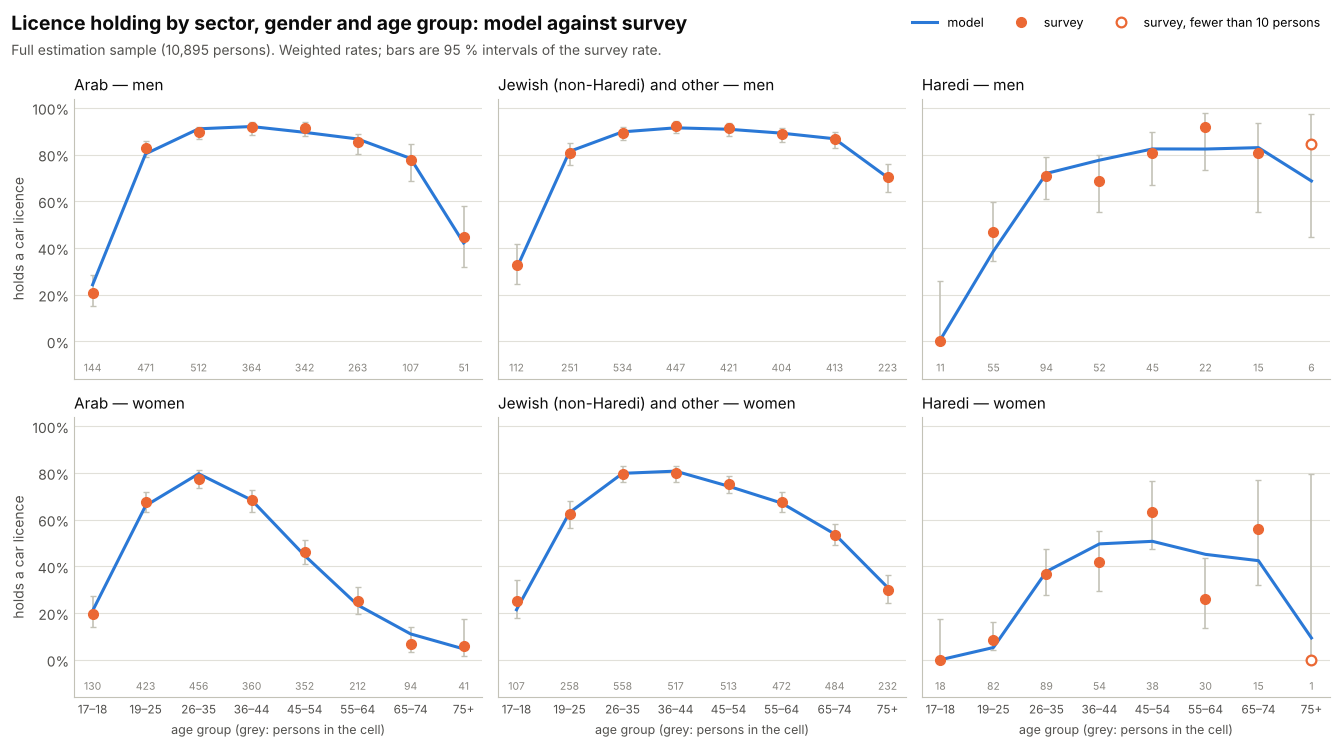

In [8]:
def wilson(p, n, z=1.96):
    n = np.maximum(n, 1e-9); c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h

def cells(t, p):
    t = t.assign(p=p, g=agegrp(t.age))
    c = t.groupby(['sec', 'male', 'g'], observed=False).apply(lambda x: pd.Series({'persons': len(x), 'observed': wmean(x.lic, x.w), 'predicted': wmean(x.p, x.w)})).reset_index()
    c['lo'], c['hi'] = wilson(c.observed.fillna(0), c.persons); c['z'] = (c.observed - c.predicted) / np.sqrt(c.predicted * (1 - c.predicted) / c.persons.clip(lower=1))
    return c

def chart(c, title, subtitle, path):
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.6), sharex=True, sharey=True)
    x = np.arange(len(AGE_LABELS))
    for j, s in enumerate(SEC_ORDER):
        for i, m in enumerate((1, 0)):
            ax = axes[i, j]; q = c[(c.sec == s) & (c.male == m)].set_index('g').reindex(AGE_LABELS)
            ok = q.persons > 0; big = q.persons >= 10
            ax.plot(x[ok], q.predicted[ok], '-', color=BLUE, lw=2.2, label='model', zorder=3)
            ax.errorbar(x[ok], q.observed[ok], yerr=[(q.observed - q.lo)[ok].clip(lower=0), (q.hi - q.observed)[ok].clip(lower=0)], fmt='none', ecolor=AXIS, elinewidth=1.2, capsize=2.5, zorder=2)
            ax.plot(x[ok & big], q.observed[ok & big], 'o', color=ORANGE, ms=7, label='survey', zorder=4)
            ax.plot(x[ok & ~big], q.observed[ok & ~big], 'o', mfc='white', mec=ORANGE, mew=1.6, ms=7, label='survey, fewer than 10 persons', zorder=4)
            for xi, n in zip(x, q.persons.fillna(0).astype(int)): ax.text(xi, -0.085, f'{n}', ha='center', va='top', fontsize=7.5, color=MUTED)
            ax.set_title(f"{SEC_NAME[s]} — {'men' if m else 'women'}", fontsize=11, loc='left', color=INK)
            ax.set_ylim(-0.16, 1.04); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_yticklabels([f'{v:.0%}' for v in np.arange(0, 1.01, 0.2)])
            ax.set_xticks(x); ax.set_xticklabels(AGE_LABELS, fontsize=8.5); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
            for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
            for sp in ('left', 'bottom'): ax.spines[sp].set_color(AXIS)
            ax.tick_params(colors=INK2, length=0)
            if j == 0: ax.set_ylabel('holds a car licence', color=INK2)
            if i == 1: ax.set_xlabel('age group (grey: persons in the cell)', color=INK2, fontsize=9)
    h, l = axes[0, 0].get_legend_handles_labels(); u = dict(zip(l, h))
    for a in axes.ravel():
        hh, ll_ = a.get_legend_handles_labels(); u.update(dict(zip(ll_, hh)))
    fig.legend(u.values(), u.keys(), loc='upper right', bbox_to_anchor=(0.99, 0.985), ncol=3, frameon=False, fontsize=9)
    fig.text(0.012, 0.975, title, ha='left', va='top', fontsize=14, fontweight='bold', color=INK)
    fig.text(0.012, 0.935, subtitle, ha='left', va='top', fontsize=10, color=INK2)
    fig.tight_layout(rect=(0, 0, 1, 0.91)); fig.savefig(path, dpi=180, bbox_inches='tight'); plt.show()

d['p'] = P(par, SPEC, d)
cal_full = cells(d, d.p); cal_full.to_csv(f'{OUT}/model_vs_data_full_sample.csv', index=False)
chart(cal_full, 'Licence holding by sector, gender and age group: model against survey',
      f'Full estimation sample ({len(d):,} persons). Weighted rates; bars are 95 % intervals of the survey rate.', f'{OUT}/model_vs_data_full_sample.png')

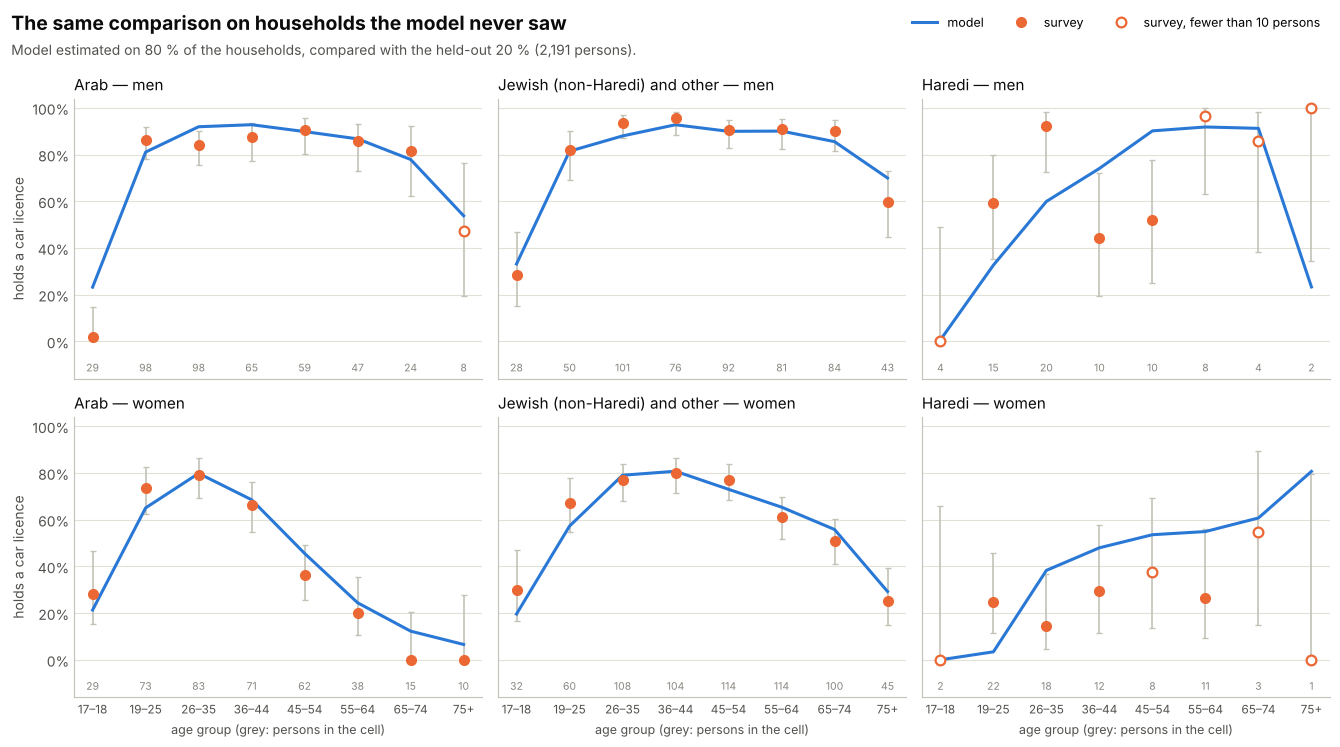

In [9]:
r80 = lm.fit(train, SPEC, FILL); test['p'] = P(r80.params, SPEC, test)
cal_hold = cells(test, test.p); cal_hold.to_csv(f'{OUT}/model_vs_data_holdout.csv', index=False)
chart(cal_hold, 'The same comparison on households the model never saw',
      f'Model estimated on 80 % of the households, compared with the held-out 20 % ({len(test):,} persons).', f'{OUT}/model_vs_data_holdout.png')

In [10]:
def summary(c, name):
    q = c[c.persons >= 10]
    return pd.Series({'cells with 10+ persons': len(q), 'outside ±2 standard errors': int((q.z.abs() > 2).sum()),
                      'mean absolute gap (points)': 100 * (q.observed - q.predicted).abs().mean(),
                      'largest gap (points)': 100 * (q.observed - q.predicted).abs().max()}, name=name)
fit_summary = pd.concat([summary(cal_full, 'full sample'), summary(cal_hold, 'held-out 20 %')], axis=1).T
by_sg = test.assign(Sector=test.sec.map(SEC_NAME), Gender=np.where(test.male == 1, 'men', 'women')).groupby(['Sector', 'Gender']).apply(
    lambda x: pd.Series({'persons': len(x), 'observed': wmean(x.lic, x.w), 'predicted': wmean(x.p, x.w)}))
by_sg.to_csv(f'{OUT}/holdout_by_sector_gender.csv')
print(f"held-out households, all persons: observed {wmean(test.lic, test.w):.3f}, predicted {wmean(test.p, test.w):.3f}")
display(fit_summary.round(1)); display(by_sg.round(3))
worst = cal_hold[cal_hold.persons >= 10].assign(gap=lambda x: x.observed - x.predicted).sort_values('gap', key=abs, ascending=False).head(6)
worst.assign(sec=worst.sec.map(SEC_NAME), male=np.where(worst.male == 1, 'men', 'women'))[['sec', 'male', 'g', 'persons', 'observed', 'predicted', 'z']].round(3)

held-out households, all persons: observed 0.691, predicted 0.698


,cells with 10+ persons,outside ±2 standard errors,mean absolute gap (points),largest gap (points)
full sample,46.0,1.0,2.8,19.2
held-out 20 %,39.0,8.0,9.9,38.3


persons  observed  predicted
Sector                        Gender                              
Arab                          men       428.0     0.792      0.820
                              women     381.0     0.499      0.513
Haredi                        men        73.0     0.730      0.669
                              women      77.0     0.267      0.397
Jewish (non-Haredi) and other men       555.0     0.844      0.833
                              women     677.0     0.637      0.634

,sec,male,g,persons,observed,predicted,z
28,Haredi,men,45–54,10.0,0.518,0.901,-4.068
26,Haredi,men,26–35,20.0,0.921,0.599,2.933
27,Haredi,men,36–44,10.0,0.441,0.741,-2.163
21,Haredi,women,55–64,11.0,0.266,0.549,-1.887
25,Haredi,men,19–25,15.0,0.593,0.327,2.202
18,Haredi,women,26–35,18.0,0.145,0.383,-2.073


Calibration along the zone variables (full sample), which the charts above do not show:

In [11]:
zc = pd.concat([
    d.assign(k='index ' + pd.cut(lm.clean_soceco(d.SOCECO, FILL), [0, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 10], labels=['1–2', '3', '4', '5', '6', '7', '8–10']).astype(str)),
    d.assign(k='ring ' + d.TABAAT.astype(int).astype(str))]).groupby('k').apply(
    lambda x: pd.Series({'persons': len(x), 'observed': wmean(x.lic, x.w), 'predicted': wmean(x.p, x.w)}))
zc.to_csv(f'{OUT}/calibration_zone.csv'); zc.round(3)

,persons,observed,predicted
k,,,
index 1–2,974.0,0.549,0.555
index 3,2643.0,0.641,0.643
index 4,969.0,0.693,0.678
index 5,2213.0,0.692,0.698
index 6,1370.0,0.756,0.745
index 7,1346.0,0.785,0.797
index 8–10,1380.0,0.876,0.874
ring 1,3385.0,0.700,0.700
ring 2,2233.0,0.683,0.683


## 5. From persons to zones: age and gender inside the forecast's bands

The forecast gives persons per zone, sector and age band (0–7, 8–18, 19–25, 26–35, 36–64,
65+), without gender or single years of age. Inside each band × sector cell the persons are
spread over single years of age and gender with the survey's weighted distribution; a cell
with fewer than 30 survey persons takes the all-sector distribution of its band. Persons
under 17 hold no licence.

In [12]:
shares = lm.within_band_shares(allp); shares.to_csv(f'{OUT}/age_gender_shares_within_band.csv', index=False)
s2 = shares.assign(adult=shares.age >= 17, m=shares.share * shares.male, a=shares.share * shares.age)
chk = s2.groupby(['band', 'sec'], sort=False).agg(survey_persons=('n_survey', 'first'), fallback=('fallback', 'first'), share_men=('m', 'sum'),
                                                 mean_age=('a', 'sum')).join(s2[s2.adult].groupby(['band', 'sec']).share.sum().rename('share_17_plus')).fillna(0)
chk.round(3)

survey_persons  fallback  share_men  mean_age  share_17_plus
band  sec                                                               
0_7   rest            1110     False      0.516     3.741          0.000
      ara              820     False      0.540     3.778          0.000
      ort              432     False      0.500     3.397          0.000
8_18  rest            1306     False      0.477    12.999          0.182
      ara             1460     False      0.548    13.128          0.195
      ort              325     False      0.519    12.396          0.108
19_25 rest             511     False      0.497    22.191          1.000
      ara              896     False      0.556    22.061          1.000
      ort              137     False      0.343    22.709          1.000
26_35 rest            1092     False      0.476    30.757          1.000
      ara              969     False      0.540    29.973          1.000
      ort              183     False      0.502    29.092          1.000
36_64 rest            2777     False      0.463    49.347          1.000
      ara             1901     False      0.501    48.847          1.000
      ort              241     False      0.519    46.962          1.000
65    rest            1353     False      0.472    72.742          1.000
      ara              294     False      0.551    72.733          1.000
      ort               37     False      0.564    70.820          1.000

## 6. Application: 2020, 2040 and 2050

**The premise: a licence, once obtained, is not given up.** The 2017 profile falls with age in
every group, most steeply for women. Under the premise that fall is a difference between
generations, not something that happens to a person as they age.

- **static** — the model's 2017 rate at the person's age. It applies the fall to everyone, so
  it is a lower bound.
- **cohort** (adopted) — with *a0* the cohort's age in 2017, the rate is the highest value of
  the 2017 profile between *a0* (not below 17) and the person's age in the forecast year:
  - a cohort already past the profile's peak in 2017 keeps the rate it had then (Arab women
    aged 50 in 2017 keep their 38 %, at 73 in 2040 and at 83 in 2050);
  - a cohort that had not reached the peak takes the peak of its gender, sector and zone;
  - where the profile still rises with age (Haredi men and women), the cohort follows it up.
- two runs of the first version of the rule, kept as sensitivity: new cohorts take the mean
  30–39 rate rather than the peak, and cohorts aged 30+ in 2017 keep their rate — without
  giving-up, and with a giving-up curve after 65 (the decline of rest-sector men relative to
  their rate at 65: for a zone of mean index 0.95 at 75, 0.73 at 80, 0.48 at 85).

The scenario's own socio-economic index and ring are used for each year.

In [13]:
def zonal(name):
    return pd.read_csv('Input/Zonal_2020.csv' if name == '2020' else f'Input/Demographic_Forecast/Zonal_{name}.csv', encoding='cp1255')

RUNS = {'static': dict(method='static'), 'cohort': dict(method='peak'),
        'cohort_window_30_39': dict(method='cohort', giving_up=False), 'cohort_window_30_39_giving_up': dict(method='cohort')}
long, det = [], {}
for scen, year in [('base', 2020)] + SCEN:
    z = zonal('2020' if scen == 'base' else f'{scen}_{year}')
    base = None
    for run, kw in RUNS.items():
        g = lm.apply_zonal(par, SPEC, z, shares, year, FILL, detail=True, **kw)
        det[(scen, year, run)] = g
        o = g.groupby(['TAZ_ID', 'sec', 'band'], sort=False).agg(persons=('n', 'sum'), persons_17_plus=('n', lambda v: v[g.loc[v.index, 'age'] >= 17].sum()), holders=('holders', 'sum')).reset_index()
        if base is None: base = o[['TAZ_ID', 'sec', 'band', 'persons', 'persons_17_plus']].copy()
        base[f'holders_{run}'] = o.holders.to_numpy()
    pop = float(z.POPULATION.sum()); assert abs(base.persons.sum() - pop) < 1e-6 * pop, (base.persons.sum(), pop)
    assert base.filter(like='holders').notna().all().all() and (base.filter(like='holders').to_numpy() <= base[['persons_17_plus']].to_numpy() + 1e-6).all()
    long.append(base.assign(scenario=scen, year=year))
taz = pd.concat(long, ignore_index=True)
taz = taz[['scenario', 'year', 'TAZ_ID', 'sec', 'band', 'persons', 'persons_17_plus'] + [f'holders_{r}' for r in RUNS]]
taz.round(3).to_csv(f'{OUT}/licence_holders_taz_sector_band.csv', index=False)
print(f"{len(taz):,} rows: 5 population sets x 781 zones x 3 sectors x 6 bands; population reconciles with the zonal files")

70,290 rows: 5 population sets x 781 zones x 3 sectors x 6 bands; population reconciles with the zonal files


**Base-year check.** The model applied to the 2020 zonal population, against the survey's
weighted rate for persons aged 17 and over. The two populations are not the same — the zonal
file covers all 781 zones with its own sector and age mix — so only a rough agreement is
expected, and the by-sector comparison is the fairer one.

In [14]:
b = taz[taz.scenario == 'base']
surv = d.groupby('sec').apply(lambda x: wmean(x.lic, x.w)).rename('survey 2017, weighted')
chk = b.groupby('sec').apply(lambda x: x.holders_static.sum() / x.persons_17_plus.sum()).rename('model on 2020 zonal, static').to_frame().join(surv)
chk.loc['all'] = [b.holders_static.sum() / b.persons_17_plus.sum(), wmean(d.lic, d.w)]
chk['share of 17+ (zonal 2020)'] = b.groupby('sec').persons_17_plus.sum() / b.persons_17_plus.sum(); chk.loc['all', 'share of 17+ (zonal 2020)'] = 1
chk['share of 17+ (survey)'] = d.groupby('sec').w.sum() / d.w.sum(); chk.loc['all', 'share of 17+ (survey)'] = 1
chk.rename(index=SEC_NAME).round(3)

,"model on 2020 zonal, static","survey 2017, weighted",share of 17+ (zonal 2020),share of 17+ (survey)
sec,,,,
Arab,0.677,0.680,0.404,0.439
Haredi,0.475,0.498,0.026,0.029
Jewish (non-Haredi) and other,0.750,0.743,0.570,0.532
all,0.713,0.709,1.000,1.000


## 7. Results: licence holders in 2040 and 2050

In [15]:
def tot(x): return pd.Series({'population': x.persons.sum(), 'aged 17+': x.persons_17_plus.sum(), **{r: x[f'holders_{r}'].sum() for r in RUNS}})
S = taz.groupby(['scenario', 'year'], sort=False).apply(tot)
for r in RUNS: S[f'rate {r}'] = S[r] / S['aged 17+']
S['cohort − static (holders)'] = S.cohort - S.static; S['cohort − static (points)'] = 100 * (S['rate cohort'] - S['rate static'])
S.to_csv(f'{OUT}/summary_by_scenario.csv')
show = S[['population', 'aged 17+', 'static', 'cohort', 'rate static', 'rate cohort', 'cohort − static (holders)', 'cohort − static (points)']]
show.style.format({'population': '{:,.0f}', 'aged 17+': '{:,.0f}', 'static': '{:,.0f}', 'cohort': '{:,.0f}', 'rate static': '{:.1%}', 'rate cohort': '{:.1%}',
                   'cohort − static (holders)': '{:+,.0f}', 'cohort − static (points)': '{:+.1f}'})

In [16]:
SS = taz.groupby(['scenario', 'year', 'sec'], sort=False).apply(tot)
SS['rate static'] = SS.static / SS['aged 17+']; SS['rate cohort'] = SS.cohort / SS['aged 17+']; SS['rate cohort, 30–39 window'] = SS.cohort_window_30_39 / SS['aged 17+']
SS = SS.rename(index=SEC_NAME, level='sec'); SS.to_csv(f'{OUT}/summary_by_scenario_sector.csv')
SS[['aged 17+', 'static', 'cohort', 'rate static', 'rate cohort', 'rate cohort, 30–39 window']].style.format(
    {'aged 17+': '{:,.0f}', 'static': '{:,.0f}', 'cohort': '{:,.0f}', 'rate static': '{:.1%}', 'rate cohort': '{:.1%}', 'rate cohort, 30–39 window': '{:.1%}'})

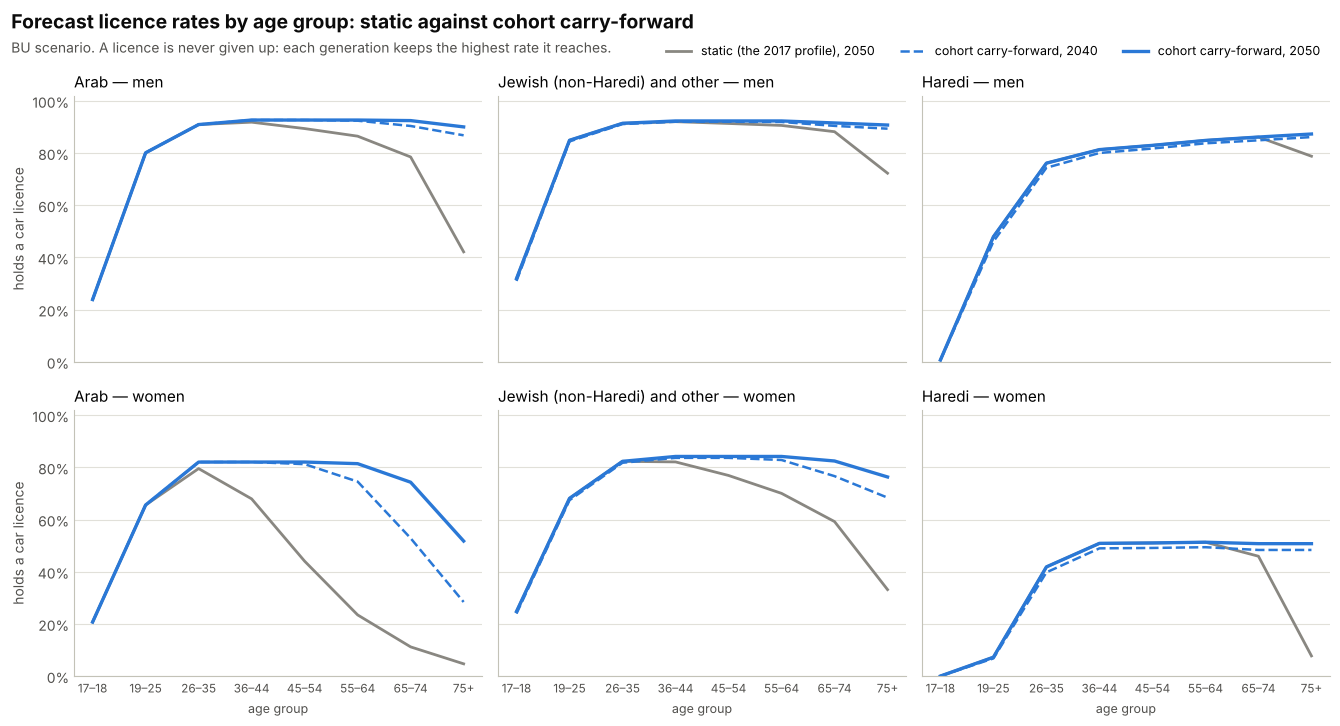

In [17]:
# by sector, gender and age group: where the cohort rule departs from the static one
rows = []
for (scen, year, run), g in det.items():
    if run not in ('static', 'cohort'): continue
    a = g[g.age >= 17].assign(g=agegrp(g.age[g.age >= 17]))
    q = a.groupby(['sec', 'male', 'g'], observed=False).agg(persons=('n', 'sum'), holders=('holders', 'sum')).reset_index()
    rows.append(q.assign(scenario=scen, year=year, run=run))
sg = pd.concat(rows).pivot_table(index=['scenario', 'year', 'sec', 'male', 'g'], columns='run', values='holders', observed=False).join(
    pd.concat(rows).query("run == 'static'").set_index(['scenario', 'year', 'sec', 'male', 'g']).persons).reset_index()
sg['rate_static'] = sg.static / sg.persons; sg['rate_cohort'] = sg.cohort / sg.persons
sg.round(4).to_csv(f'{OUT}/rates_by_sector_gender_age_group.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.4), sharex=True, sharey=True); x = np.arange(len(AGE_LABELS))
for j, s in enumerate(SEC_ORDER):
    for i, m in enumerate((1, 0)):
        ax = axes[i, j]
        q0 = sg[(sg.scenario == 'base') & (sg.sec == s) & (sg.male == m)].set_index('g').reindex(AGE_LABELS)
        q = sg[(sg.scenario == 'BU') & (sg.year == 2050) & (sg.sec == s) & (sg.male == m)].set_index('g').reindex(AGE_LABELS)
        q4 = sg[(sg.scenario == 'BU') & (sg.year == 2040) & (sg.sec == s) & (sg.male == m)].set_index('g').reindex(AGE_LABELS)
        ax.plot(x, q.rate_static, '-', color=MUTED, lw=2, label='static (the 2017 profile), 2050')
        ax.plot(x, q4.rate_cohort, '--', color=BLUE, lw=1.8, label='cohort carry-forward, 2040')
        ax.plot(x, q.rate_cohort, '-', color=BLUE, lw=2.4, label='cohort carry-forward, 2050')
        ax.set_title(f"{SEC_NAME[s]} — {'men' if m else 'women'}", fontsize=11, loc='left')
        ax.set_ylim(0, 1.02); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_yticklabels([f'{v:.0%}' for v in np.arange(0, 1.01, 0.2)])
        ax.set_xticks(x); ax.set_xticklabels(AGE_LABELS, fontsize=8.5); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
        for sp in ('left', 'bottom'): ax.spines[sp].set_color(AXIS)
        ax.tick_params(colors=INK2, length=0)
        if j == 0: ax.set_ylabel('holds a car licence', color=INK2)
        if i == 1: ax.set_xlabel('age group', color=INK2, fontsize=9)
h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc='upper right', bbox_to_anchor=(0.99, 0.945), ncol=3, frameon=False, fontsize=9)
fig.text(0.012, 0.975, 'Forecast licence rates by age group: static against cohort carry-forward', ha='left', va='top', fontsize=14, fontweight='bold', color=INK)
fig.text(0.012, 0.935, 'BU scenario. A licence is never given up: each generation keeps the highest rate it reaches.', ha='left', va='top', fontsize=10, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.91)); fig.savefig(f'{OUT}/forecast_static_vs_cohort_by_age_group.png', dpi=180, bbox_inches='tight'); plt.show()

### Sensitivity of the cohort forecast, and its sampling uncertainty

The sensitivity runs are the first version of the cohort rule (30–39 window), without and
with giving-up after 65. The interval is sampling
uncertainty only: 200 draws of the coefficients from their household-clustered covariance,
each carried through the cohort rule (zones grouped by index and ring, which is exact for
this model). It does not cover the rule's assumptions or the demographic scenario.

In [18]:
sens = S[[f'rate {r}' for r in RUNS]].copy(); sens.columns = list(RUNS)
rng = np.random.default_rng(SEED); draws = rng.multivariate_normal(par.to_numpy(), res.cov_params().to_numpy(), size=200)
ci = []
for scen, year in [('base', 2020)] + SCEN:
    z = zonal('2020' if scen == 'base' else f'{scen}_{year}')
    z = z.assign(SOCECO=lm.clean_soceco(z.SOCECO, FILL), SETTL_SIZE=1)
    acols = [f'AGE_{b}_{lm.ZCOL[s]}' for b in lm.BANDS for s in lm.SECTORS]
    zg = z.groupby(['SOCECO', 'TABAAT'], as_index=False)[acols].sum().assign(SETTL_SIZE=1); zg['TAZ_ID'] = np.arange(len(zg))
    ref = lm.apply_zonal(par, SPEC, zg, shares, year, FILL, method='peak')
    assert abs(ref.holders.sum() - S.loc[(scen, year), 'cohort']) < 1e-6 * ref.holders.sum()
    adults = taz[(taz.scenario == scen) & (taz.year == year)].groupby('sec').persons_17_plus.sum()
    sims = []
    for b_ in draws:
        o = lm.apply_zonal(pd.Series(b_, index=par.index), SPEC, zg, shares, year, FILL, method='peak').groupby('sec').holders.sum()
        sims.append(pd.concat([o / adults, pd.Series({'all': o.sum() / adults.sum()})]))
    sims = pd.DataFrame(sims)
    for k_ in sims.columns:
        ci.append({'scenario': scen, 'year': year, 'group': SEC_NAME.get(k_, 'all'), 'cohort rate': (ref.groupby('sec').holders.sum() / adults).get(k_, ref.holders.sum() / adults.sum()),
                   'low 2.5 %': sims[k_].quantile(0.025), 'high 97.5 %': sims[k_].quantile(0.975)})
ci = pd.DataFrame(ci); ci.to_csv(f'{OUT}/cohort_rate_sampling_interval.csv', index=False); sens.to_csv(f'{OUT}/sensitivity_rates.csv')
display(sens.style.format('{:.1%}'))
ci.pivot_table(index=['scenario', 'year'], columns='group', values=['cohort rate', 'low 2.5 %', 'high 97.5 %'], sort=False).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False).style.format('{:.1%}')

In [19]:
# licence holders per zone (all sectors and bands), for mapping and for the next model in the chain
zt = taz.groupby(['scenario', 'year', 'TAZ_ID'], sort=False)[['persons', 'persons_17_plus', 'holders_static', 'holders_cohort']].sum().reset_index()
zt['rate_cohort_17_plus'] = (zt.holders_cohort / zt.persons_17_plus).where(zt.persons_17_plus > 0)
zt.round(3).to_csv(f'{OUT}/licence_holders_taz.csv', index=False)
print(sorted(os.listdir(OUT)))
zt[zt.persons_17_plus > 500].groupby(['scenario', 'year'], sort=False).rate_cohort_17_plus.describe(percentiles=[.1, .5, .9]).round(3)

['age_gender_shares_within_band.csv', 'calibration_zone.csv', 'coefficients.csv', 'coefficients_covariance.csv', 'cohort_rate_sampling_interval.csv', 'forecast_static_vs_cohort_by_age_group.png', 'holdout_by_model.csv', 'holdout_by_sector_gender.csv', 'licence_holders_taz.csv', 'licence_holders_taz_sector_band.csv', 'model_vs_data_full_sample.csv', 'model_vs_data_full_sample.png', 'model_vs_data_holdout.csv', 'model_vs_data_holdout.png', 'rates_by_sector_gender_age_group.csv', 'sensitivity_rates.csv', 'specification_ladder.csv', 'summary_by_scenario.csv', 'summary_by_scenario_sector.csv']


count   mean    std    min    10%    50%    90%    max
scenario year                                                        
base     2020  588.0  0.730  0.114  0.337  0.589  0.721  0.873  0.938
BU       2040  595.0  0.774  0.124  0.291  0.596  0.794  0.899  0.955
         2050  582.0  0.777  0.138  0.289  0.546  0.811  0.904  0.959
HS       2040  641.0  0.777  0.121  0.291  0.611  0.796  0.895  0.954
         2050  651.0  0.779  0.135  0.286  0.557  0.813  0.902  0.957